# Dữ liệu giá nhà Amsterdam
**Nguồn trong đề:** Lab 1 — mục 1.2.2 (Matplotlib, Seaborn) và 1.3.2 bài toán 1 nhiệm vụ 2 (boxplot, violin, describe)

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab1 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
import os
HAS_HOUSE = os.path.exists("data/HousingPricesData.csv")
print("Có file HousingPricesData.csv:", HAS_HOUSE)

Có file HousingPricesData.csv: True


In [3]:
import pandas as pd
import matplotlib.pyplot as plt  # [Chỉnh] bổ sung import (đề chưa import ở mục này)
houseprices_data = pd.read_csv("data/HousingPricesData.csv")
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
# Create a PriceperSqm variable based on the Price and Area variables:
houseprices_data['PriceperSqm'] = houseprices_data['Price']/houseprices_data['Area']

In [4]:
houseprices_sorted = houseprices_data.sort_values('Price', ascending = False)
houseprices_sorted.head()

,Zip,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15101.522843
837,1075 AH,5850000.0,480,14,12187.500000
305,1016 AE,4900000.0,623,13,7865.168539
103,1017 ZP,4550000.0,497,13,9154.929577
179,1012 JS,4495000.0,178,5,25252.808989


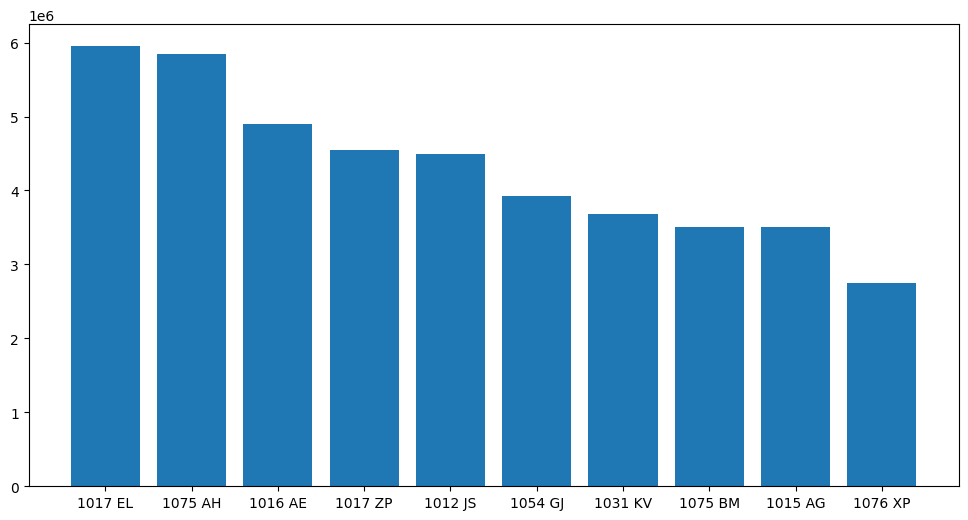

In [5]:
# case 1: basic
plt.figure(figsize= (12,6))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
plt.bar(x,y)
plt.show()

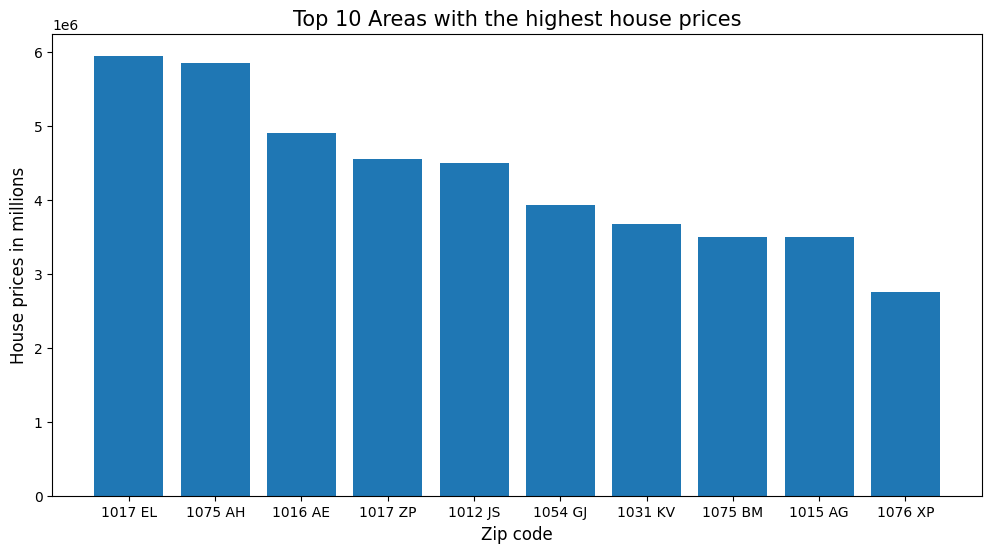

In [6]:
# case 2: advanced 1
plt.figure(figsize= (12,6))
plt.bar(x,y)
plt.title('Top 10 Areas with the highest house prices', fontsize=15)
plt.xlabel('Zip code', fontsize = 12)
plt.xticks(fontsize=10)
plt.ylabel('House prices in millions', fontsize=12)
plt.yticks(fontsize=10)
plt.show()

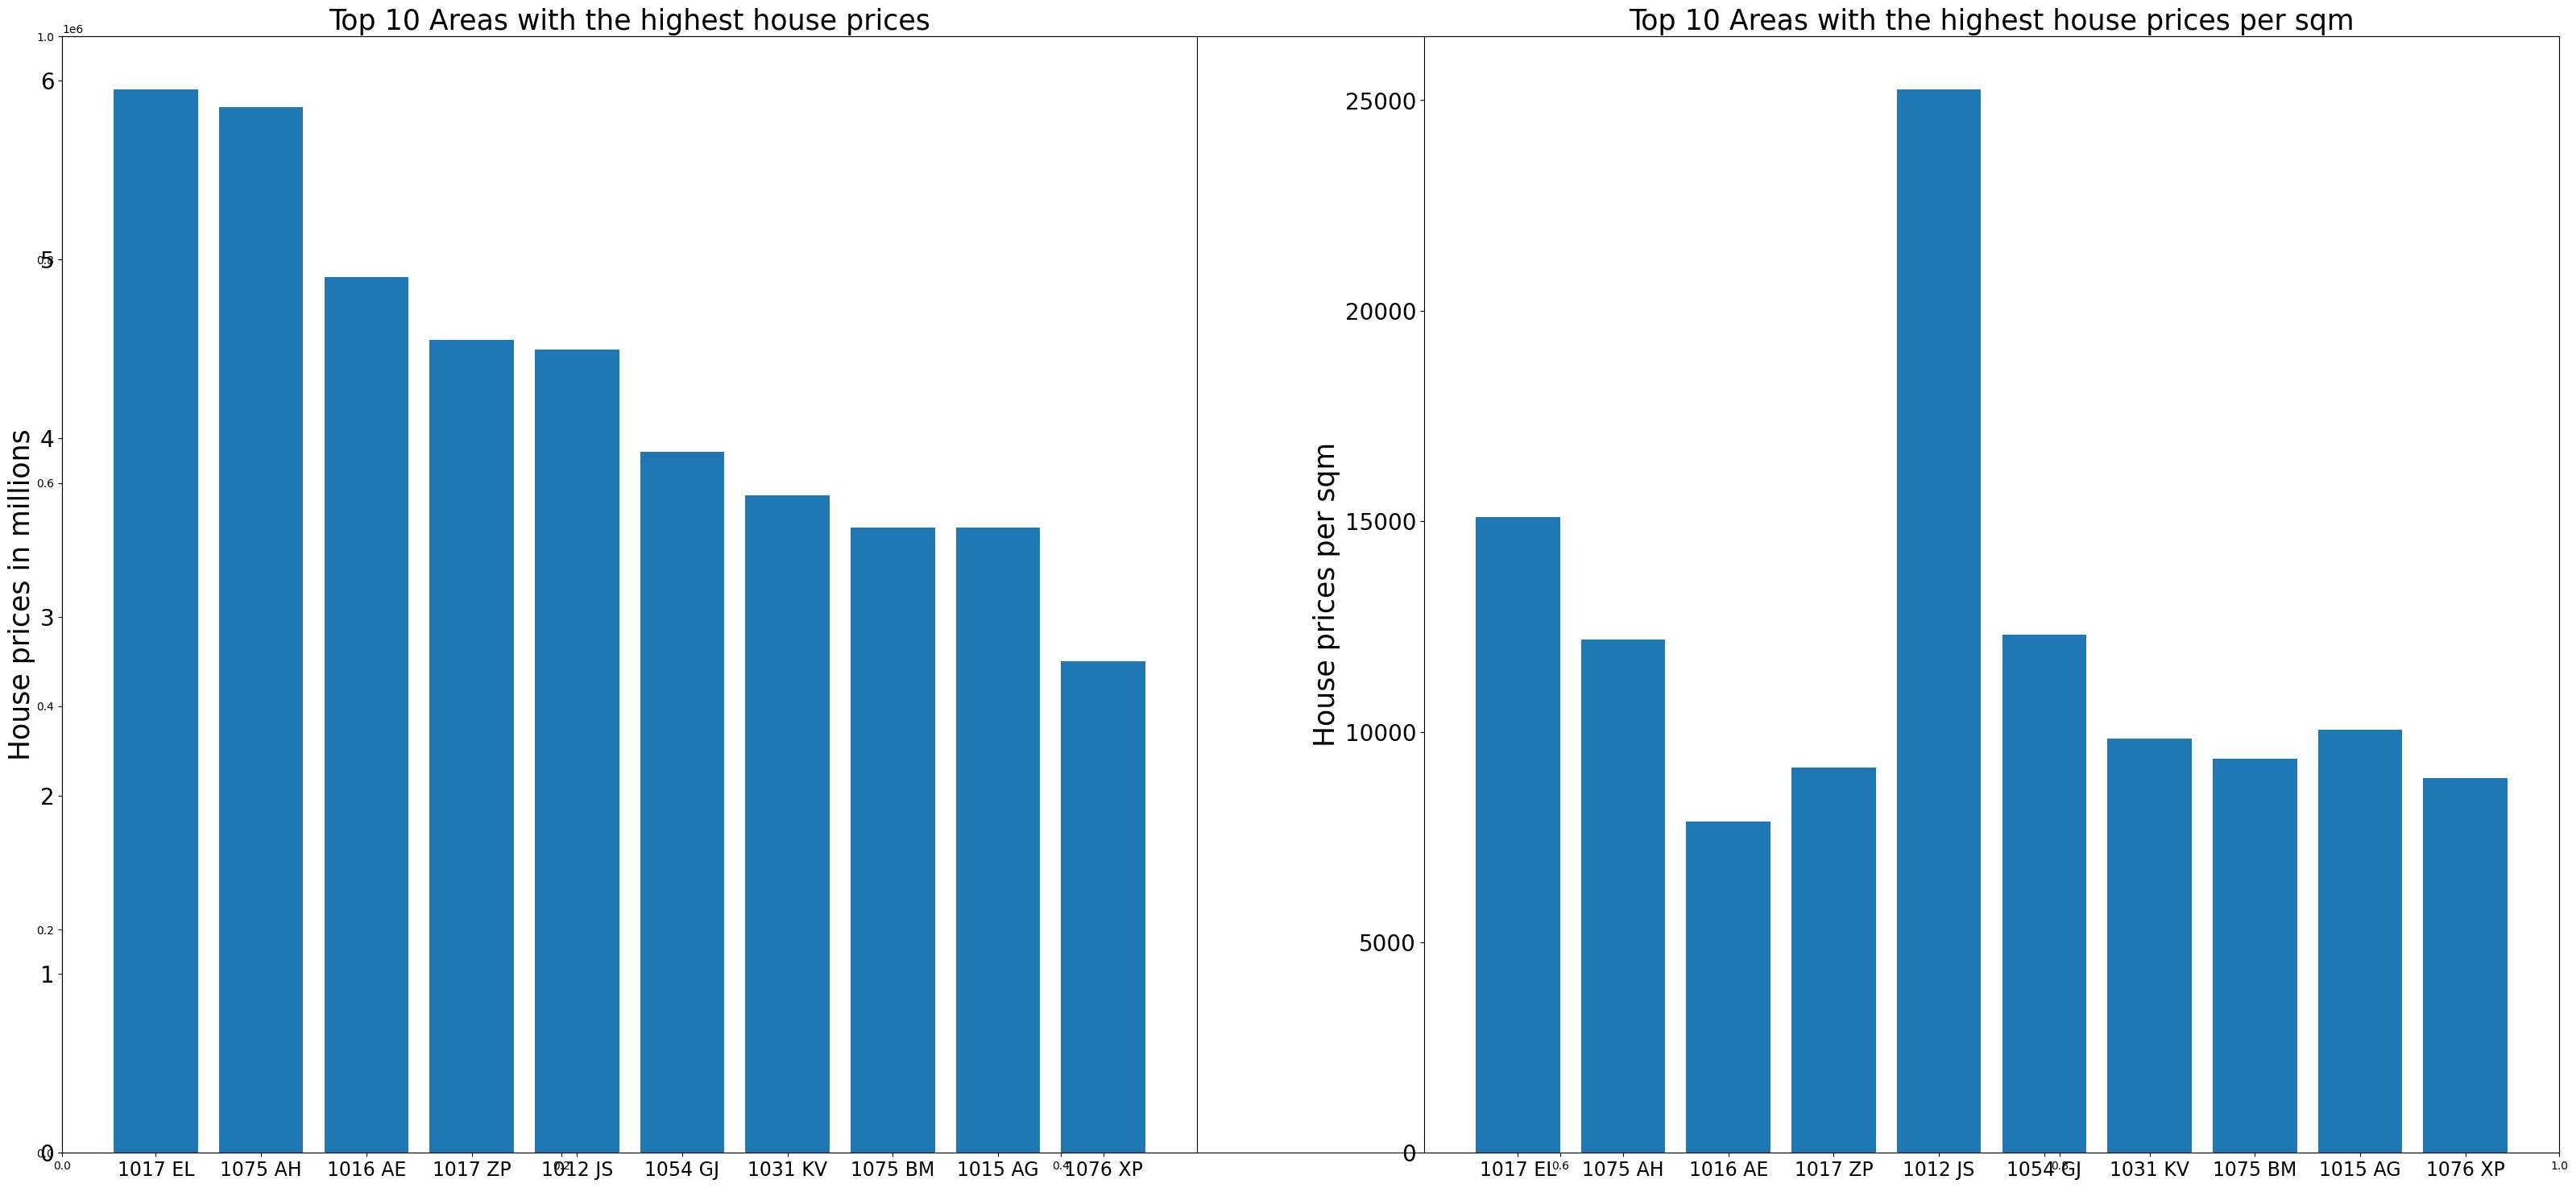

In [7]:
# case 3: advanced 2
fig, ax = plt.subplots(figsize=(40,18))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
y1 = houseprices_sorted['PriceperSqm'][0:10]
plt.subplot(1,2,1)
plt.bar(x,y)
plt.xticks(fontsize=17)
plt.ylabel('House prices in millions', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices', fontsize=25)
plt.subplot(1,2,2)
plt.bar(x,y1)
plt.xticks(fontsize=17)
plt.ylabel('House prices per sqm', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices per sqm', fontsize=25)
plt.show()

**3. Trực quan hóa dữ liệu với thư viện Seaborn**

<Axes: xlabel='Zip', ylabel='Price'>

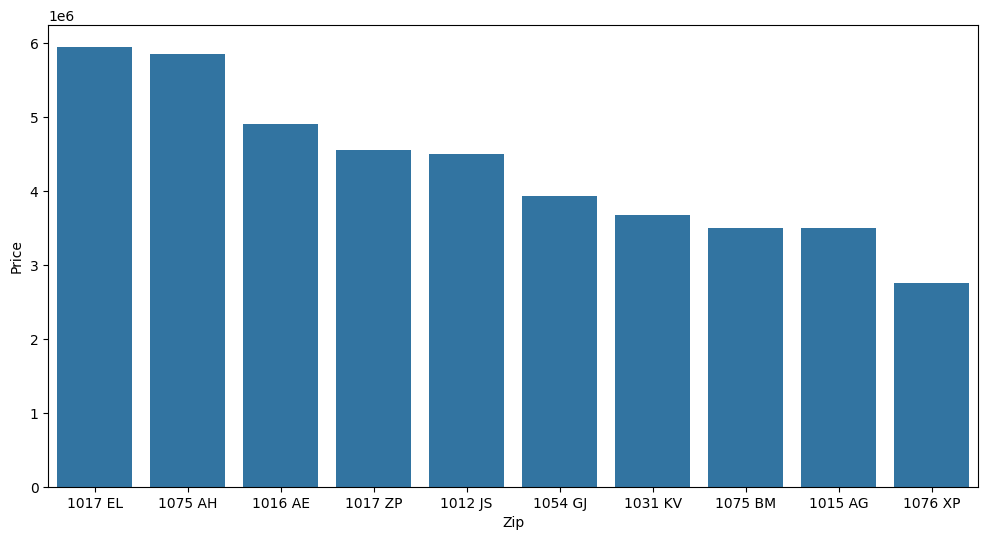

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
# case 1: basic
plt.figure(figsize= (12,6))
data = houseprices_sorted[0:10]
sns.barplot(data= data, x= 'Zip',y = 'Price')

Text(0.5, 1.0, 'Top 10 Areas with the highest house prices')

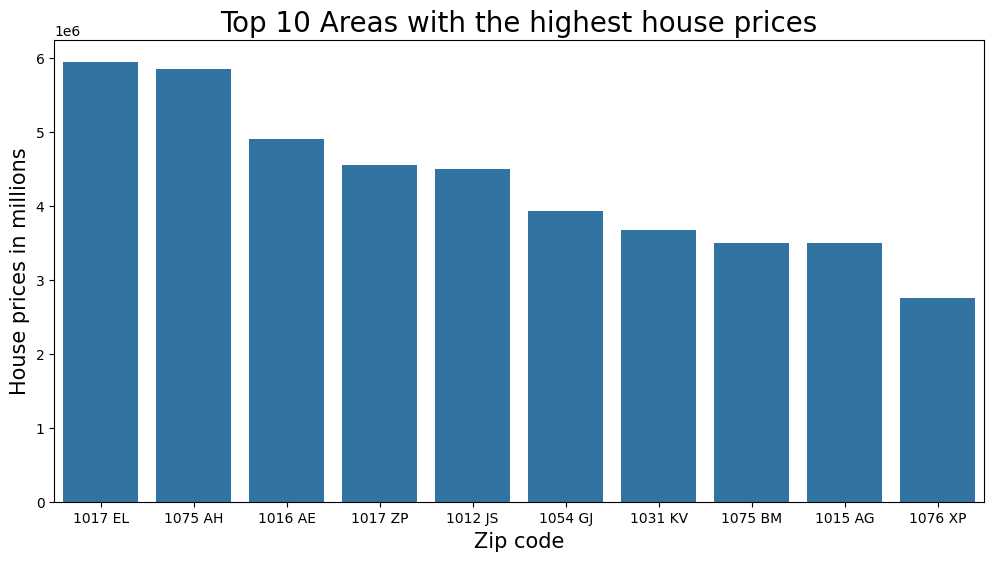

In [9]:
# case 2: advanced 1
plt.figure(figsize= (12,6))
data = houseprices_sorted[0:10]
ax = sns.barplot(data= data, x= 'Zip',y = 'Price')
ax.set_xlabel('Zip code',fontsize = 15)
ax.set_ylabel('House prices in millions', fontsize = 15)
ax.set_title('Top 10 Areas with the highest house prices', fontsize= 20)

Text(0.5, 1.0, 'Top 10 Areas with the highest price per sqm')

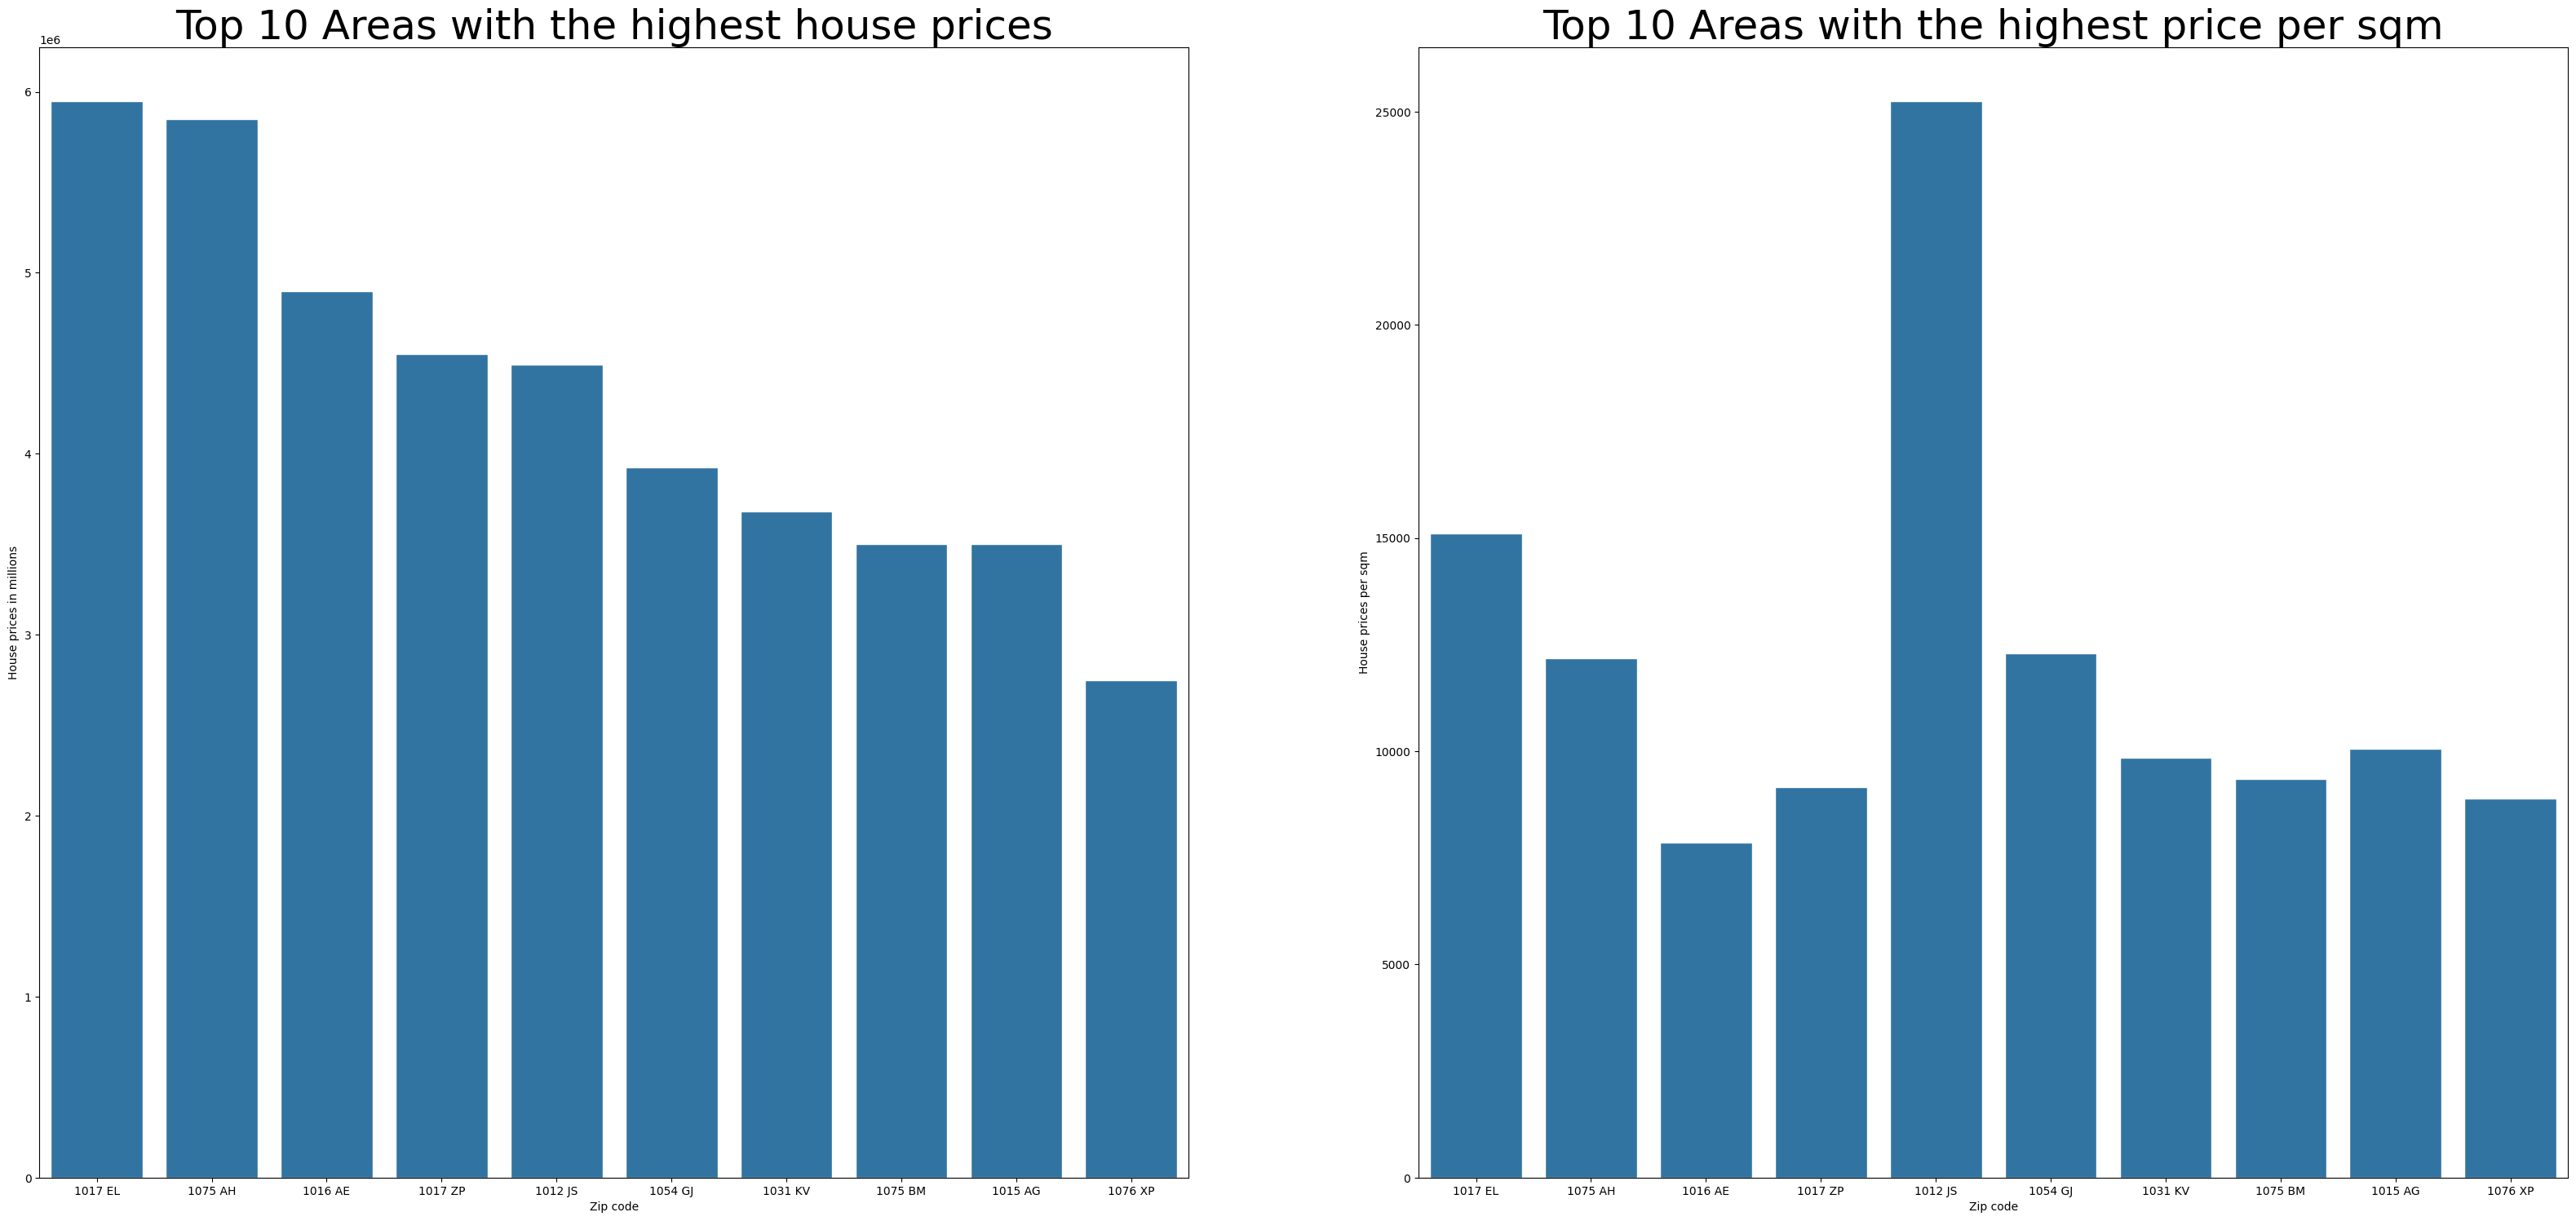

In [10]:
# case 3: view multiple perspectives at once
fig, ax = plt.subplots(1, 2,figsize=(40,18))
data = houseprices_sorted[0:10]
sns.set(font_scale = 3)
ax1 = sns.barplot(data= data, x= 'Zip',y = 'Price', ax = ax[0])
ax1.set_xlabel('Zip code')
ax1.set_ylabel('House prices in millions')
ax1.set_title('Top 10 Areas with the highest house prices')
ax2 = sns.barplot(data= data, x= 'Zip',y = 'PriceperSqm',
ax=ax[1])
ax2.set_xlabel('Zip code')
ax2.set_ylabel('House prices per sqm')
ax2.set_title('Top 10 Areas with the highest price per sqm')

<Axes: xlabel='Price'>

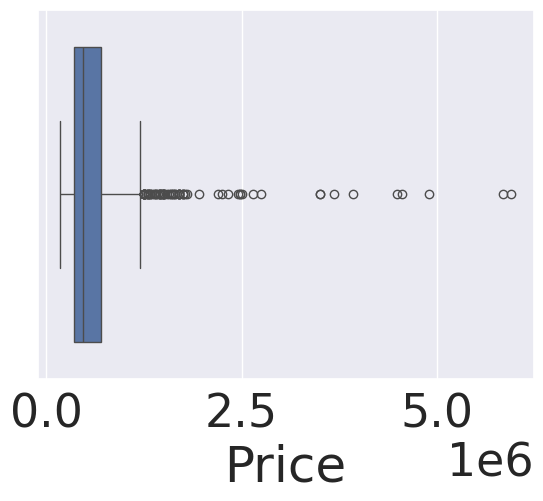

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
houseprices_data = pd.read_csv("data/HousingPricesData.csv")
houseprices_data = houseprices_data[['Zip','Price','Area','Room']]
# case 1: Create a boxplot using the boxplot method
sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])

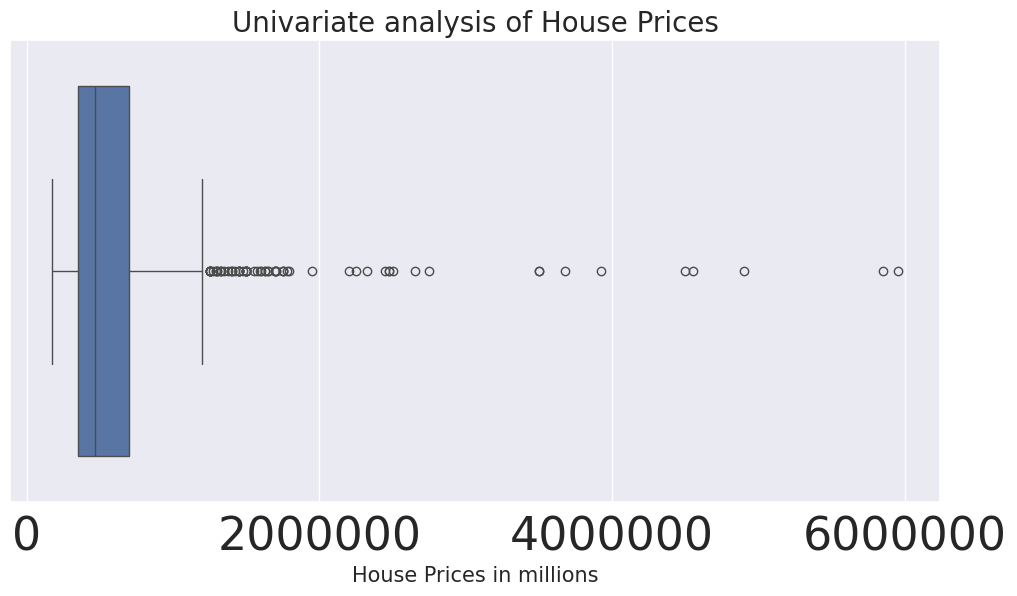

In [12]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')

<Axes: xlabel='Price'>

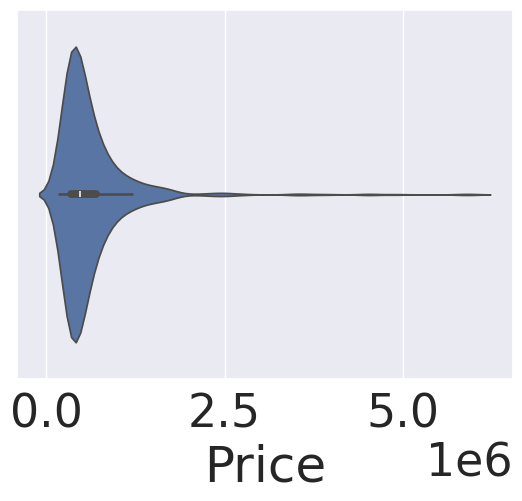

In [13]:
# case 1: basic
sns.violinplot(data = houseprices_data, x= houseprices_data["Price"])

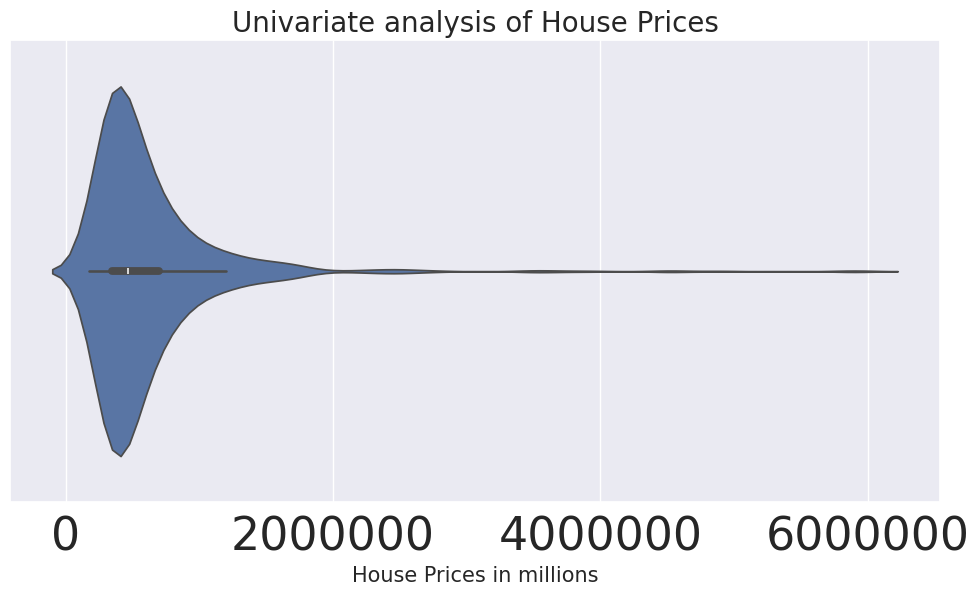

In [14]:
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.violinplot(data = houseprices_data, x=houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')

In [15]:
houseprices_data.describe()

,Price,Area,Room
count,9.200000e+02,924.000000,924.000000
mean,6.220654e+05,95.952381,3.571429
std,5.389942e+05,57.447436,1.592332
min,1.750000e+05,21.000000,1.000000
25%,3.500000e+05,60.750000,3.000000
50%,4.670000e+05,83.000000,3.000000
75%,7.000000e+05,113.000000,4.000000
max,5.950000e+06,623.000000,14.000000
